## Part 1: Import Required Libraries

In [12]:
# Data handling
import numpy as np
import pandas as pd

# File path handling
import os
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt

# Deep learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Image preprocessing
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print('TensorFlow version:', tf.__version__)
print('GPUs available:', tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Part 2: Define Dataset Paths

In [13]:
import os

base_dir = None
for root, dirs, files in os.walk('/kaggle/input'):
    if {'train', 'test', 'validation'}.issubset(set(dirs)):
        base_dir = root
        break

print('base_dir =', base_dir)

train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')
validation_dir = os.path.join(base_dir, 'validation')

for name, p in [('train', train_dir), ('test', test_dir), ('validation', validation_dir)]:
    print(f'{name:<11}: {p} | exists: {os.path.isdir(p)}')

base_dir = /kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images
train      : /kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train | exists: True
test       : /kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test | exists: True
validation : /kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation | exists: True


> If the path does not exist on your Kaggle notebook, run `!find /kaggle/input -maxdepth 3 -type d` to see where the dataset was mounted and adjust `base_dir`.

## Part 3: Count Images in Each Class

In [14]:
IMG_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')

def count_images_per_class(folder_path):
    """Takes a dataset folder, reads every class sub-folder and
    returns a dictionary {class_name: number_of_images}."""
    counts = {}
    for class_name in sorted(os.listdir(folder_path)):
        class_path = os.path.join(folder_path, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len([f for f in os.listdir(class_path)
                                      if f.lower().endswith(IMG_EXTENSIONS)])
    return counts

train_counts = count_images_per_class(train_dir)
test_counts = count_images_per_class(test_dir)
validation_counts = count_images_per_class(validation_dir)

print('TRAIN:', train_counts)
print()
print('TEST:', test_counts)
print()
print('VALIDATION:', validation_counts)

TRAIN: {'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}

TEST: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}

VALIDATION: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


## Part 4: Create a Summary DataFrame

In [15]:
train_df = pd.DataFrame(list(train_counts.items()), columns=['Vegetable', 'Train Count'])
test_df = pd.DataFrame(list(test_counts.items()), columns=['Vegetable', 'Test Count'])
validation_df = pd.DataFrame(list(validation_counts.items()), columns=['Vegetable', 'Validation Count'])

summary_df = (train_df
              .merge(test_df, on='Vegetable')
              .merge(validation_df, on='Vegetable'))

display(summary_df)
print('Totals ->', summary_df[['Train Count', 'Test Count', 'Validation Count']].sum().to_dict())

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


Totals -> {'Train Count': 15000, 'Test Count': 3000, 'Validation Count': 3000}


## Part 5: Visualize Class Distribution

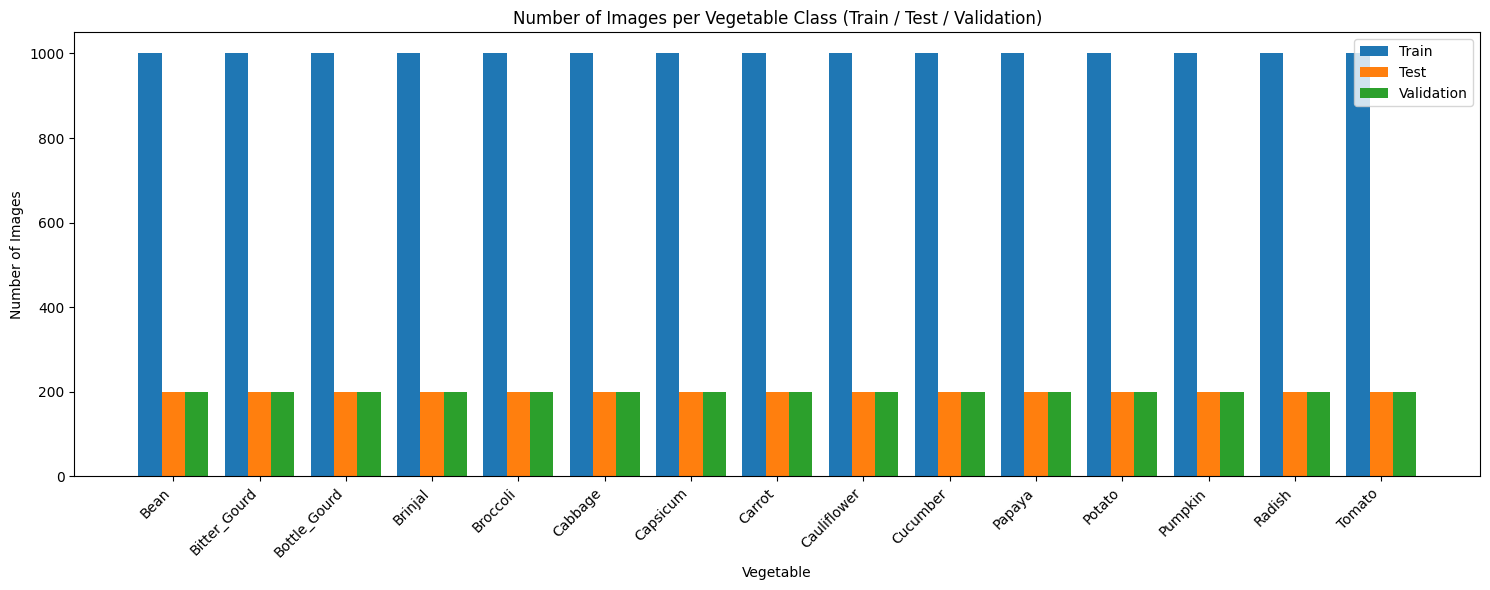

In [16]:
x = np.arange(len(summary_df))
width = 0.27

plt.figure(figsize=(15, 6))
plt.bar(x - width, summary_df['Train Count'], width, label='Train')
plt.bar(x, summary_df['Test Count'], width, label='Test')
plt.bar(x + width, summary_df['Validation Count'], width, label='Validation')

plt.xticks(x, summary_df['Vegetable'], rotation=45, ha='right')
plt.xlabel('Vegetable')
plt.ylabel('Number of Images')
plt.title('Number of Images per Vegetable Class (Train / Test / Validation)')
plt.legend()
plt.tight_layout()
plt.show()

Is the dataset balanced?
Yes. The count table and the bar chart show that all 15 classes have exactly the same number of images in each split: 1000 per class in train (15,000 total) and 200 per class in test and validation (3,000 each). No class dominates, so the model is not biased toward any class and accuracy is a fair metric.

## Part 6: Image Preprocessing and Augmentation

In [17]:
VAL_SPLIT = 0.2

# Training generator: rescaling + augmentation + validation split
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=VAL_SPLIT
)

# Validation generator: ONLY rescaling + validation split (no augmentation)
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=VAL_SPLIT
)

## Part 7: Load Images Using `flow_from_directory`

In [18]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=SEED
)

val_ds = val_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=SEED,
    shuffle=False
)

class_names = list(train_ds.class_indices.keys())
num_classes = len(class_names)
print('Classes:', class_names)
print('Number of classes:', num_classes)

Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.
Classes: ['Bean', 'Bitter_Gourd', 'Bottle_Gourd', 'Brinjal', 'Broccoli', 'Cabbage', 'Capsicum', 'Carrot', 'Cauliflower', 'Cucumber', 'Papaya', 'Potato', 'Pumpkin', 'Radish', 'Tomato']
Number of classes: 15


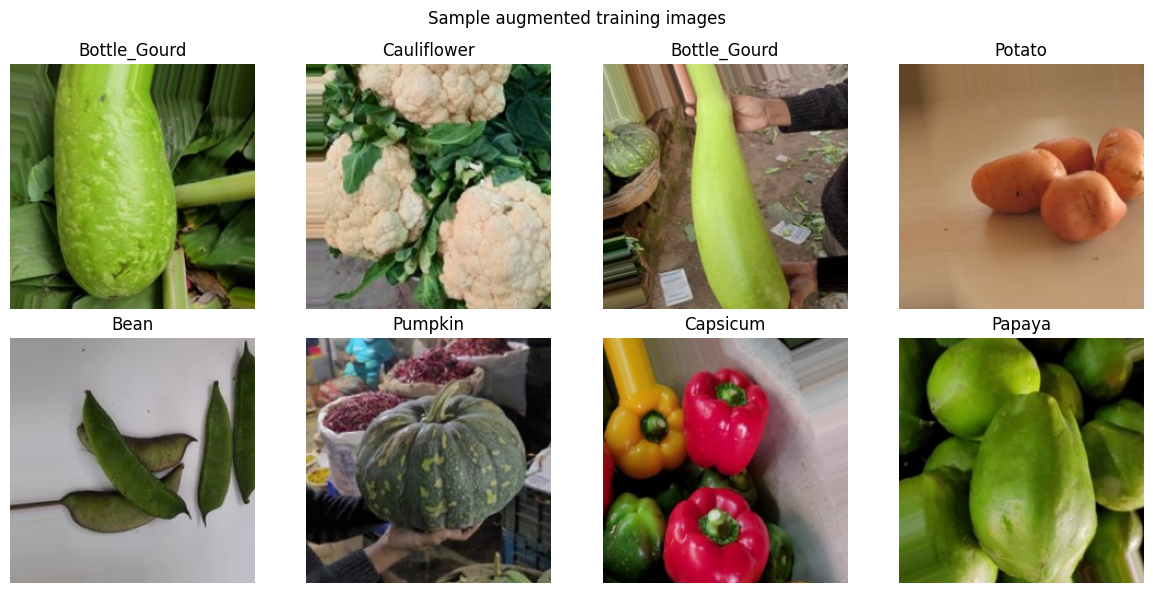

In [19]:
# Quick look at a batch of augmented training images
images, labels = next(train_ds)
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i])
    plt.title(class_names[np.argmax(labels[i])])
    plt.axis('off')
plt.suptitle('Sample augmented training images')
plt.tight_layout()
plt.show()

## Part 8: Build the CNN Model (Keras Sequential)

In [20]:
from tensorflow.keras.layers import Input

model = Sequential([
    Input(shape=(224, 224, 3)),

    # Convolution Block 1
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Convolution Block 2
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Convolution Block 3
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Fully connected layers
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(15, activation='softmax')
])

## Part 9: Compile the Model

In [21]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

Model explanation
• Number of convolutional layers: 3 (with 32, 64 and 128 filters). The model summary shows about 44.4 million trainable parameters, most of them in the Dense layer after Flatten.
• Purpose of pooling layers: They shrink the feature maps, which reduces computation and the number of parameters, and helps the model handle small shifts in the image.
• Purpose of dropout: It randomly turns off 50% of the neurons during training, which prevents overfitting.
• Why softmax is used: It turns the 15 outputs into probabilities that sum to 1, so the class with the highest probability is the prediction. It suits multi-class classification.

In [22]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Part 10: Train the Model

In [23]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping]
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 842s 2s/step - accuracy: 0.4304 - loss: 1.7041 - val_accuracy: 0.6710 - val_loss: 1.0328
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 166s 442ms/step - accuracy: 0.6759 - loss: 0.9785 - val_accuracy: 0.7673 - val_loss: 0.6872
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 172s 458ms/step - accuracy: 0.7659 - loss: 0.7316 - val_accuracy: 0.8993 - val_loss: 0.3329
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 160s 426ms/step - accuracy: 0.8057 - loss: 0.6087 - val_accuracy: 0.8727 - val_loss: 0.3966
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 167s 444ms/step - accuracy: 0.8363 - loss: 0.5177 - val_accuracy: 0.9363 - val_loss: 0.2131
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 167s 444ms/step - accuracy: 0.8658 - loss: 0.4205 - val_accuracy: 0.9540 - val_loss: 0.1577
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 166s 443ms/step - accuracy: 0.8786 - loss: 0.3874 - val_accuracy: 0.9597 - val_loss: 0.1481
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 165s 439ms/step - accuracy: 0.8922 - lo

Why is EarlyStopping useful?
It stops training when the validation loss stops improving (after 5 epochs without improvement). This prevents overfitting and saves time, and restoring the best weights keeps the best version of the model. In my run, training reached the 20-epoch limit, and the best weights were restored from epoch 15 (validation loss 0.0650, validation accuracy 98.13%).

## Part 11: Evaluate the Model

To get a fair measurement on the training data, we evaluate it with a generator that applies **no augmentation** (rescaling only) over the same training subset.

In [24]:
# Non-augmented view of the training subset, used only for evaluation
train_eval_datagen = ImageDataGenerator(rescale=1./255, validation_split=VAL_SPLIT)
train_eval_ds = train_eval_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=SEED,
    shuffle=False
)

train_loss, train_acc = model.evaluate(train_eval_ds, verbose=1)
val_loss, val_acc = model.evaluate(val_ds, verbose=1)

print(f'Training Accuracy   : {train_acc:.4f}')
print(f'Validation Accuracy : {val_acc:.4f}')
print(f'Training Loss       : {train_loss:.4f}')
print(f'Validation Loss     : {val_loss:.4f}')
print(f'Accuracy gap (train - val): {train_acc - val_acc:.4f}')

Found 12000 images belonging to 15 classes.
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 85ms/step - accuracy: 0.9877 - loss: 0.0414
94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 93ms/step - accuracy: 0.9813 - loss: 0.0650
Training Accuracy   : 0.9877
Validation Accuracy : 0.9813
Training Loss       : 0.0414
Validation Loss     : 0.0650
Accuracy gap (train - val): 0.0064


Is there a large difference between training and validation accuracy?
My results: training accuracy = 98.77%, validation accuracy = 98.13% (training loss 0.0414, validation loss 0.0650).
No, the difference is very small (about 0.6 percentage points), so the model is not overfitting and generalizes well to new images. Validation loss (0.0650) is slightly higher than training loss (0.0414), which is normal. The model also scored 97.87% accuracy on the separate test set, which confirms this. (If training accuracy had been much higher than validation accuracy, that would indicate overfitting.)

## Part 12: Plot Accuracy and Loss Curves

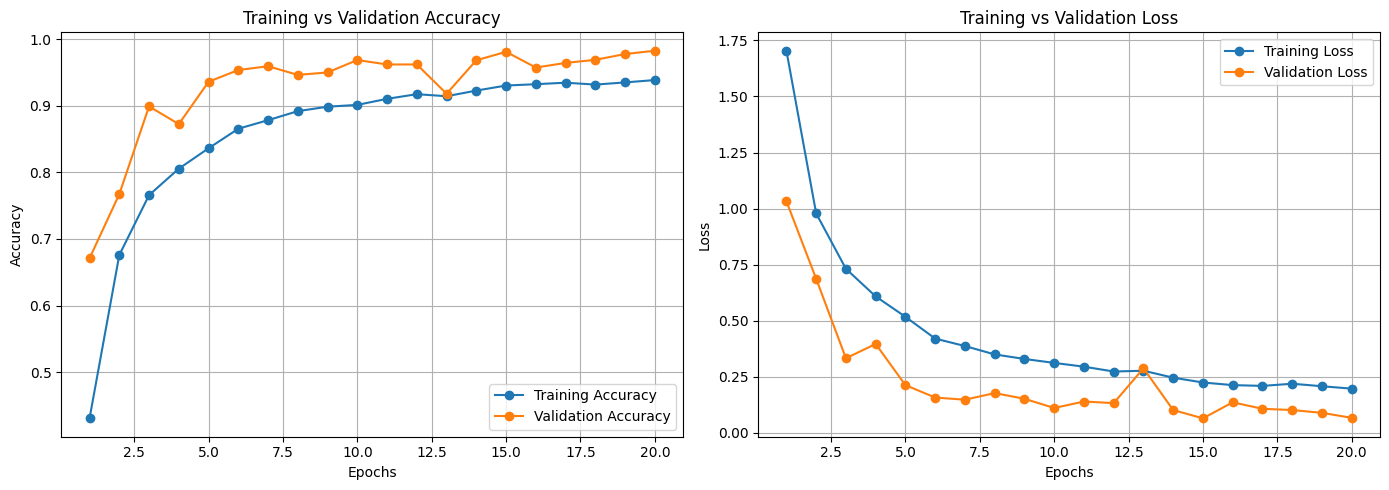

In [25]:
epochs_range = range(1, len(history.history['accuracy']) + 1)

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'], marker='o', label='Training Accuracy')
plt.plot(epochs_range, history.history['val_accuracy'], marker='o', label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'], marker='o', label='Training Loss')
plt.plot(epochs_range, history.history['val_loss'], marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [26]:
test_datagen = ImageDataGenerator(rescale=1./255)
test_ds = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f'Test Accuracy: {test_acc:.4f}')
print(f'Test Loss    : {test_loss:.4f}')

Found 3000 images belonging to 15 classes.
94/94 ━━━━━━━━━━━━━━━━━━━━ 158s 2s/step - accuracy: 0.9787 - loss: 0.0674
Test Accuracy: 0.9787
Test Loss    : 0.0674
